# Modeling

Code is in `src/features.py`, `src/model.py` and `predict.py`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from features import TARGET, load_data, market_calendar
from model import (
                   HOLDOUT_START,
                   LINEAR_FEATURES,
                   SELECTION_STARTS,
                   BaselineModel,
                   LightGBMModel,
                   LinearModel,
                   evaluate,
                   walk_forward_folds,
)

sns.set_theme(style="whitegrid")
train, valid, december = load_data()
calendar = market_calendar(train, valid)

## Split

validation.csv (Nov-Dec) is the real test set and comes after all the labels, so a random split would leak future prices. Using walk-forward folds instead: train on everything before a cutoff, test on the next 2 months (same horizon as Nov-Dec).

| | Train | Test |
|---|---|---|
| Selection fold 1 | Jan-Apr | May-Jun |
| Selection fold 2 | Jan-Jun | Jul-Aug |
| Holdout | Jan-Aug | Sep-Oct |
| Final | Jan-Oct | Nov-Dec |

Weight medians and the outlier filter are refit in each fold. Picking the model with the lowest average clean MAE on the two selection folds.

In [2]:
pd.DataFrame([{"fold": s.strftime("%b"), "train rows": len(f), "eval rows": len(t)}
              for s, f, t in walk_forward_folds(train, SELECTION_STARTS + [HOLDOUT_START])]).set_index("fold")

,train rows,eval rows
fold,,
May,19110,9696
Jul,28806,9671
Sep,38477,9523


## Models

All predict log(rate per mile) and are trained without the corrupted labels.

- baseline: median rate per mile by equipment and distance decile
- lightgbm: trees on the same inputs plus the date
- linear: Huber regression on distance terms, weight, equipment, coordinates, city dummies, daily market index. Three versions for handling time:
  - trend: linear time trend
  - none: no time term
  - recent 56d: no trend, shifted to the price level of the last 56 days

In [3]:
candidates = {
    "baseline": lambda: BaselineModel(calendar),
    "lightgbm": lambda: LightGBMModel(calendar),
    "linear [trend]": lambda: LinearModel(calendar, level="trend"),
    "linear [none]": lambda: LinearModel(calendar, level="none"),
    "linear [recent 56d]": lambda: LinearModel(calendar),
}
selection = pd.concat({name: evaluate(make, train, SELECTION_STARTS) for name, make in candidates.items()}, names=["model"])
summary = selection.groupby("model", sort=False).mean()
summary.insert(0, "clean MAE Jul", selection["clean MAE"].xs("Jul", level="fold"))
summary.insert(0, "clean MAE May", selection["clean MAE"].xs("May", level="fold"))
summary.round(2)

,clean MAE May,clean MAE Jul,MAE,RMSE,MdAPE %,bias %,clean MAE
model,,,,,,,
baseline,148.57,83.16,167.96,647.74,4.64,-4.53,115.87
lightgbm,57.46,106.83,134.60,632.16,3.04,0.04,82.14
linear [trend],45.84,97.42,124.15,627.29,2.89,0.44,71.63
linear [none],61.24,53.97,110.43,630.92,2.02,-3.06,57.61
linear [recent 56d],55.95,45.70,103.73,628.65,1.77,-2.40,50.83


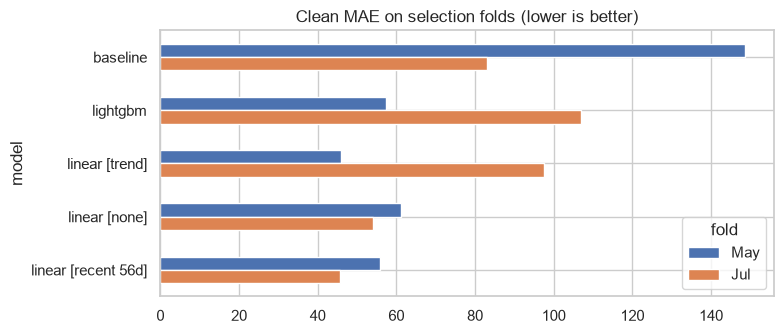

In [4]:
ax = selection["clean MAE"].unstack("fold")[["May", "Jul"]].reindex(candidates).plot.barh(figsize=(8, 3.5))
ax.set_title("Clean MAE on selection folds (lower is better)"); ax.invert_yaxis(); plt.tight_layout(); plt.show()

Going with linear [recent 56d].
- trend and lightgbm both blow up on Jul-Aug (the Jan-Jun trend picks up the spring rise; trees can't extrapolate dates)
- no time term is stable but too low
- recent 56d is stable and closest on level

## Which features help?

Same linear [recent 56d] model, adding feature groups one at a time. Scored on the selection folds.

In [5]:
base = ["inv_distance", "log_distance", "weight_k", "weight_missing", "weight_capped", "is_flatbed", "is_reefer"]
coords = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]
steps = {
    "distance + weight + equipment": dict(features=base, city_dummies=False),
    "+ market index": dict(features=base + ["mi_day"], city_dummies=False),
    "+ coordinates": dict(features=base + ["mi_day"] + coords, city_dummies=False),
    "+ city dummies (final)": dict(features=base + ["mi_day"] + coords),
    "final without market index": dict(features=base + coords),
}
ablation = pd.concat({name: evaluate(lambda kw=kw: LinearModel(calendar, **kw), train, SELECTION_STARTS)
                      for name, kw in steps.items()}, names=["features"])
out = ablation["clean MAE"].unstack("fold")[["May", "Jul"]]
out["mean clean MAE"] = out.mean(axis=1)
out["mean MdAPE %"] = ablation["MdAPE %"].groupby("features").mean()
out.reindex(steps).round(2)

fold,May,Jul,mean clean MAE,mean MdAPE %
features,,,,
distance + weight + equipment,98.48,93.40,95.94,3.70
+ market index,68.50,58.37,63.44,2.50
+ coordinates,59.80,49.72,54.76,1.98
+ city dummies (final),55.95,45.70,50.83,1.77
final without market index,92.38,81.86,87.12,3.35


The market index matters most: adding it takes clean MAE from ~96 to ~63, and dropping it from the final model puts it back at ~87. Coordinates and city dummies each add a few more points (geography). All of these stay in the final model.

## Holdout (Sep-Oct)

I looked at Sep-Oct during development (that's where I noticed the quote_signal issue), so this isn't a fully blind test.

In [6]:
holdout = pd.concat({name: evaluate(candidates[name], train, [HOLDOUT_START])
                     for name in ["linear [recent 56d]", "lightgbm", "baseline"]}, names=["model"])
holdout.droplevel("fold").round(2)

,MAE,RMSE,MdAPE %,bias %,clean MAE
model,,,,,
linear [recent 56d],134.60,641.93,3.11,-4.55,79.05
lightgbm,112.72,635.74,2.07,-3.50,56.88
baseline,134.91,638.59,3.15,-2.06,79.26


In [7]:
final_folds = pd.concat([selection.loc["linear [recent 56d]"], holdout.loc["linear [recent 56d]"]])
final_folds[["clean MAE", "MAE", "MdAPE %", "bias %"]].round(2)

,clean MAE,MAE,MdAPE %,bias %
fold,,,,
May,55.95,109.68,1.82,-2.48
Jul,45.70,97.78,1.72,-2.33
Sep,79.05,134.60,3.11,-4.55


Not better than the baseline on Sep-Oct. Prices jumped in September and the level from Jul-Aug was ~4.6% too low. LightGBM wins this fold but was bad on Jul-Aug. The linear model is the most consistent over the three folds. Rough expectation for Nov-Dec: clean MAE ~$45-80, probably on the low side if prices keep going up.

## Final model (all of Jan-Oct)

In [8]:
final = LinearModel(calendar).fit(train)
coef = pd.Series(final.linear_[1].coef_ / final.linear_[0].scale_, index=final.linear_[0].feature_names_in_)
print(f"Level shift from the last 56 days: {np.expm1(final.offset_):+.1%}")
coef[LINEAR_FEATURES].round(4).to_frame("coefficient (log rate per mile, unscaled units)")

Level shift from the last 56 days: +2.9%


,"coefficient (log rate per mile, unscaled units)"
inv_distance,0.1064
log_distance,-0.1081
weight_k,0.0031
weight_missing,-0.0007
weight_capped,-0.0166
is_flatbed,0.0784
is_reefer,0.1211
pickup_lat,-0.0024
pickup_lon,-0.0003
delivery_lat,-0.0024


In [9]:
city = coef[coef.index.str.startswith(("pickup_", "delivery_")) & ~coef.index.isin(LINEAR_FEATURES)]
print("city effects (log points): pickup range %.3f to %.3f, delivery range %.3f to %.3f" % (
    city.filter(like="pickup_").min(), city.filter(like="pickup_").max(),
    city.filter(like="delivery_").min(), city.filter(like="delivery_").max()))

city effects (log points): pickup range -0.023 to 0.026, delivery range -0.023 to 0.025


Reefer ~13% more than dry van, flatbed ~8% more, +0.1 market index ~ +1.3%.

## Predictions + December chart

In [10]:
valid_pred = final.predict(valid)
dec_pred = final.predict(december)
lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne") & (train.equipment == "Dry Van")]
print("validation predictions positive:", (valid_pred > 0).all(), " n:", len(valid_pred))
print(f"Lexington → Fort Wayne Dry Van in training: {len(lane)} loads, ${lane[TARGET].min():.0f}-${lane[TARGET].max():.0f} (median ${lane[TARGET].median():.0f})")
print(f"December predictions: ${dec_pred.min():.0f}-${dec_pred.max():.0f}")

validation predictions positive: True  n: 12000
Lexington → Fort Wayne Dry Van in training: 21 loads, $758-$934 (median $808)
December predictions: $815-$838


wrote 12000 validation and 31 december predictions



Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



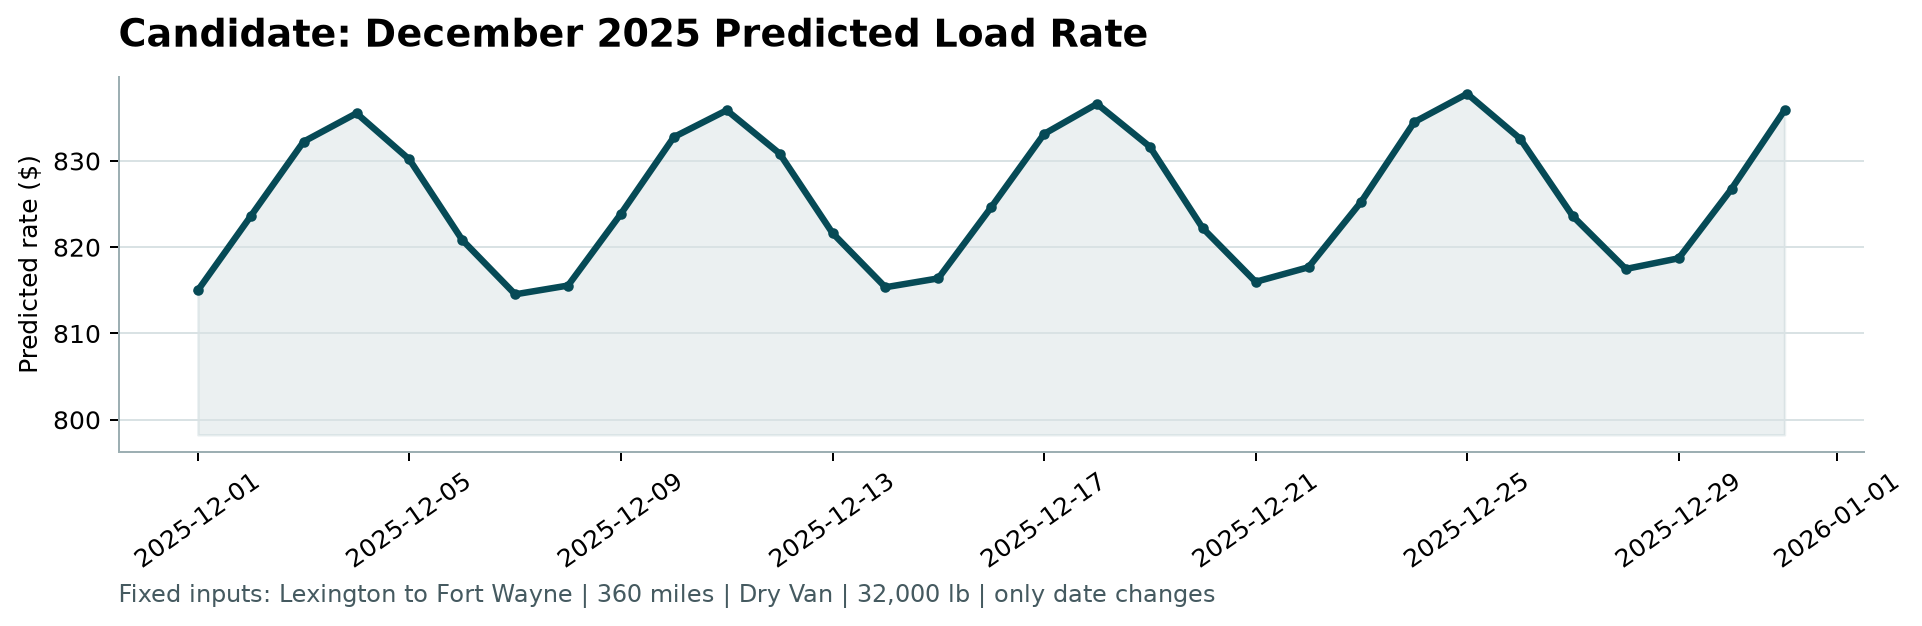

In [11]:
print(subprocess.run([sys.executable, "predict.py"], cwd=ROOT, capture_output=True, text=True).stdout)
r = subprocess.run([sys.executable, "score.py", "--predictions", "validation_predictions.csv",
                    "--december-predictions", "data/december_chart_inputs.csv"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout or r.stderr)
Image(filename=str(ROOT / "scorer_results" / "candidate_december.png"))

Only the date changes, so the chart is just the weekly market index cycle at the recent price level. No trend and no holiday effects (no December holidays in training).